# code_019 · Gradients and iterative optimization

**Book:** Chapter 4, section 4.3. **Scope:** an inspectable learning-mechanism laboratory with locally generated data. These examples do not establish real structural safety, causal effects, generalization to new materials or a competitive model benchmark. They are not exhaustive estimator-constructor studies.

Use the [quickstart](../README.md) and [pinned environment](../requirements-lock.txt). Restart the kernel and run every cell in order. Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, scikit-learn 1.9.0, CPU only on macOS ARM64. All data/helpers/imports are inside this notebook. No ordinary-run files, network downloads, credentials, GPU or private imports are needed. Allow a minute to execute and 30–60 minutes to inspect predictions and exercises. Actual timing, versions and results appear at the end and in [execution evidence](../CHAPTER_04_EXECUTION.md).

Read each prediction prompt first. Parameter values, fitted state, model/training controls, sampling assumptions and decision criteria have different roles. The [traceability guide](../CHAPTER_04_GUIDE.md) maps these mechanisms and exercises; the [stable registry](../CODE_EXAMPLES.md#code_019) preserves this ID. Every fitted assessment example declares its information boundary; pure gradient and failure checks use constructed training data only.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from scipy import special
from IPython.display import display
START=time.perf_counter();SEED=419;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,
'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,
'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 419


<a id="hand-update"></a>
## Trace four rows before a large loop

Dimensionless rows (1,0),(0,1),(1,1),(2,1) have y=(2,1,3,5) mm. For R=.5*mean((Xw-y)²), gradient is X.T@(Xw-y)/n. Start at zero and use eta=.1: gradient (-3.75,-2.25) mm gives new w=(.375,.225) mm. These are exact constructed training checks, not a population assessment.

**Predict:** why is dividing by batch size part of the gradient convention? What would summing do to the effect of changing batch size?


In [2]:
Xtiny=np.array([[1.,0.],[0.,1.],[1.,1.],[2.,1.]])
ytiny=np.array([2.,1.,3.,5.]);w=np.zeros(2)
def objective(X,y,w):return .5*np.mean((X@w-y)**2)
def gradient(X,y,w):return X.T@(X@w-y)/len(y)
g=gradient(Xtiny,ytiny,w);assert np.allclose(g,[-3.75,-2.25])
h=1e-5;numeric=np.array([(objective(Xtiny,ytiny,w+h*e)-objective(Xtiny,ytiny,w-h*e))/(2*h) for e in np.eye(2)])
assert np.allclose(g,numeric,atol=1e-9)
trace=[]
for step in range(5):
 grad=gradient(Xtiny,ytiny,w);updated=w-.1*grad
 trace.append([step,*w,objective(Xtiny,ytiny,w),*grad,*updated]);w=updated
assert np.allclose(trace[0][-2:],[.375,.225])
display(pd.DataFrame(trace,columns=['step','w1','w2','loss_mm2','grad1','grad2','new_w1','new_w2']))
RESULTS['initial_gradient_mm']=g.tolist();RESULTS['first_updated_weights_mm']=list(trace[0][-2:]);RESULTS['initial_half_MSE_mm2']=float(trace[0][3])


,step,w1,w2,loss_mm2,grad1,grad2,new_w1,new_w2
0,0,0.000000,0.000000,4.875000,-3.750000,-2.250000,0.375000,0.225000
1,1,0.375000,0.225000,3.150234,-3.018750,-1.800000,0.676875,0.405000
2,2,0.676875,0.405000,2.036199,-2.430937,-1.438594,0.919969,0.548859
3,3,0.919969,0.548859,1.316608,-1.958402,-1.148379,1.115809,0.663697
4,4,1.115809,0.663697,0.851775,-1.578514,-0.915370,1.273660,0.755234


<a id="gradient-noise"></a>
## Freeze parameters to measure gradient noise

A separate 120-row synthetic regression uses two dimensionless features and noisy mm targets. At fixed w=(0,0), every per-row gradient is explicit. Averaging all rows must reproduce the full gradient. Uniform independent sampling *with replacement* gives an unbiased batch mean with covariance equal to row-gradient covariance divided by B. We compare variance traces for B=1,8,120 over 5000 independent batches; a size-120 replacement batch is not the deterministic full batch.

**Predict:** why must w stay fixed for this variance comparison? Does a shuffled pass have exactly the same independence structure?


In [3]:
N=120;X=rng.normal(size=(N,2));X[:,1]*=.7;truth=np.array([1.4,-.8]);y=X@truth+rng.normal(0,.2,N)
w0=np.zeros(2);per_row=(X@w0-y)[:,None]*X;full=gradient(X,y,w0)
assert np.allclose(per_row.mean(0),full)
base_trace=np.var(per_row,axis=0,ddof=0).sum();noise_rows=[]
for B in [1,8,120]:
 index=rng.integers(0,N,size=(5000,B));sample=per_row[index].mean(1)
 observed=np.var(sample,axis=0,ddof=0).sum();theory=base_trace/B
 assert np.isclose(observed,theory,rtol=.12)
 noise_rows.append([B,theory,observed,*sample.mean(0)])
display(pd.DataFrame(noise_rows,columns=['B','theoretical_variance_trace','empirical_variance_trace','mean_gradient1','mean_gradient2']))
RESULTS['gradient_variance_rows']=[list(map(float,row)) for row in noise_rows]


,B,theoretical_variance_trace,empirical_variance_trace,mean_gradient1,mean_gradient2
0,1,3.656248,3.771384,-1.223999,0.429297
1,8,0.457031,0.441981,-1.184687,0.415280
2,120,0.030469,0.031308,-1.184339,0.415410


<a id="trajectories"></a>
## Same start/rate, different batch sizes

All trajectories start at zero, use eta=.08 and run 120 updates. Full objective is evaluated after every update on the same training data. Single/minibatches sample with replacement. The exposure budgets differ (120,960,14400 examples for B=1,8,full 120), so this isolates update noise and is not a wall-time or sample-efficiency benchmark. Stochastic full-objective loss need not decrease at every step. Exact least squares gives an independent convex optimum.

**Predict:** can a single stochastic step raise the full loss while using an unbiased gradient? Does the current batch loss provide the same monitoring quantity as the full loss?


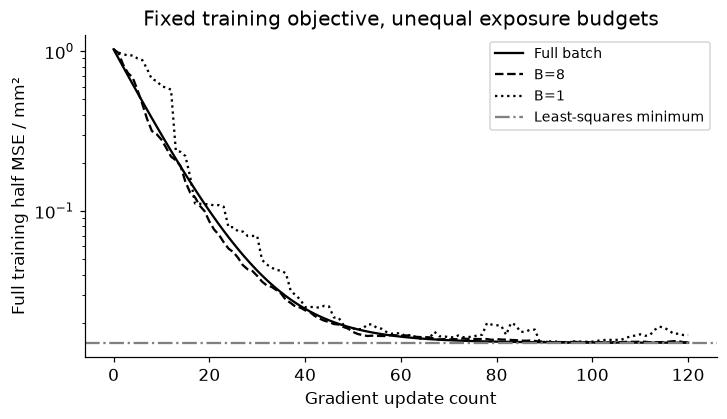

Example exposures: {'120': 14400, '8': 960, '1': 120} reference objective: 0.01497755092374371


In [4]:
reference=np.linalg.lstsq(X,y,rcond=None)[0];optimal=objective(X,y,reference);updates=120;rate=.08
paths={};exposures={};fig,ax=plt.subplots(figsize=(6.5,3.7))
for B,style,label in [(N,'-','Full batch'),(8,'--','B=8'),(1,':','B=1')]:
 step_rng=np.random.default_rng(SEED+B);w=np.zeros(2);losses=[objective(X,y,w)]
 for _ in range(updates):
  ids=np.arange(N) if B==N else step_rng.integers(0,N,B)
  w=w-rate*gradient(X[ids],y[ids],w);losses.append(objective(X,y,w))
 paths[B]=np.array(losses);exposures[str(B)]=B*updates
 ax.semilogy(losses,color='black',ls=style,label=label)
assert paths[N][-1]-optimal<1e-4 and np.all(np.diff(paths[N])<=1e-12)
assert any(np.diff(paths[1])>0) and all(np.isfinite(p).all() for p in paths.values())
ax.axhline(optimal,color='.5',ls='-.',label='Least-squares minimum');ax.set(xlabel='Gradient update count',ylabel='Full training half MSE / mm²',title='Fixed training objective, unequal exposure budgets');ax.legend(fontsize=9);plt.show()
print('Example exposures:',exposures,'reference objective:',optimal)
RESULTS['example_exposures']=exposures;RESULTS['least_squares_half_MSE_mm2']=float(optimal);RESULTS['final_half_MSE_mm2']={str(B):float(loss[-1]) for B,loss in paths.items()}


<a id="checks"></a>
## Update movement and parameter checks

Full-batch linear least squares has a positive-definite quadratic Hessian when X has full column rank. Its constant-rate bound is 0<eta<2/lambda_max. This exact bound is for this quadratic, not every neural objective. The check records the permitted rate and distinguishes gradient magnitude from actual update magnitude.


In [5]:
H=X.T@X/N;lambda_max=np.linalg.eigvalsh(H).max();limit=2/lambda_max
assert rate<limit and np.linalg.matrix_rank(X)==2
assert np.allclose(gradient(X,y,reference),0,atol=1e-12)
print('Quadratic rate limit:',limit,'chosen:',rate,'initial gradient norm:',np.linalg.norm(full),'initial update norm:',rate*np.linalg.norm(full))
RESULTS['quadratic_stability_limit']=float(limit)


Quadratic rate limit: 2.3948673997508334 chosen: 0.08 initial gradient norm: 1.2564870049253112 initial update norm: 0.1005189603940249


<a id="exercises"></a>
## Exercises and hints

1. Reproduce the second hand update, including predictions, residuals and units.
2. Compare with sampling without replacement. Derive the finite-population correction instead of assuming variance/B unchanged.
3. Compare budgets fixed by updates, exposures and measured time; state which claim each supports.
4. Use several predeclared seeds rather than selecting the smoothest stochastic path.
5. Change parameter or feature scales and inspect curvature before adjusting rate. Test the quadratic bound only in its stated setting.
6. Build a monitoring subset for a larger dataset; label it separately from development used for model selection and untouched final assessment.

**Hints:** mini/full batch loss curves are comparable only when evaluated on the same data/metric. A nominal epoch of replacement draws need not visit every row. Gradient norms and update norms answer different diagnostic questions.

**Troubleshooting:** zero or nonfinite movement deserves a direct parameter check; a correct gradient can still overshoot. [NumPy matrix multiplication](https://numpy.org/doc/stable/reference/generated/numpy.matmul.html) documents the contracted operation. Detailed neural optimizer engineering is reserved for later chapters.


In [6]:
summary={'example_id':'code_019','seed':SEED,'versions':VERSIONS,
'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['hand-calculated two-feature gradient', 'finite-difference check', 'full stochastic and minibatch updates', 'unbiased with-replacement batch gradients', 'gradient variance scaling', 'update versus exposure budgets'],
'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["hand-calculated two-feature gradient", "finite-difference check", "full stochastic and minibatch updates", "unbiased with-replacement batch gradients", "gradient variance scaling", "update versus exposure budgets"], "elapsed_seconds": 0.186, "example_id": "code_019", "hardware": "Darwin arm64 CPU", "results": {"example_exposures": {"1": 120, "120": 14400, "8": 960}, "final_half_MSE_mm2": {"1": 0.01672838896124775, "120": 0.01498544638907671, "8": 0.015030604886949017}, "first_updated_weights_mm": [0.375, 0.225], "gradient_variance_rows": [[1.0, 3.6562475377593793, 3.7713837079675807, -1.2239985481339366, 0.4292968223368261], [8.0, 0.4570309422199224, 0.4419806062276204, -1.184686541750809, 0.41528029064613475], [120.0, 0.03046872948132816, 0.031307989436926004, -1.1843385758165113, 0.4154099106268404]], "initial_gradient_mm": [-3.75, -2.25], "initial_half_MSE_mm2": 4.875, "least_squares_half_MSE_mm2": 0.01497755092374371, "quadratic_st